In [1]:
!pip install pygame
!pip install torch
!pip install imageio

In [2]:
import pygame
import random
from enum import Enum
from collections import namedtuple
import pygame
import random
from enum import Enum
from collections import namedtuple
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from collections import deque

pygame 2.6.1 (SDL 2.28.4, Python 3.12.7)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [3]:
import pygame
import random
from pygame.locals import *

# Константы
SCREEN_WIDHT = 400
SCREEN_HEIGHT = 600
SPEED = 20
GRAVITY = 2.5
GAME_SPEED = 15

GROUND_WIDHT = 2 * SCREEN_WIDHT
GROUND_HEIGHT = 100

PIPE_WIDHT = 80
PIPE_HEIGHT = 500
PIPE_GAP = 150

BACKGROUND = pygame.image.load('assets/sprites/background-day.png')
BACKGROUND = pygame.transform.scale(BACKGROUND, (SCREEN_WIDHT, SCREEN_HEIGHT))

wing = 'assets/audio/wing.wav'
hit = 'assets/audio/hit.wav'

#pygame.mixer.init()

class Bird(pygame.sprite.Sprite):
    def __init__(self):
        pygame.sprite.Sprite.__init__(self)
        self.images = [
            pygame.image.load('assets/sprites/bluebird-upflap.png').convert_alpha(),
            pygame.image.load('assets/sprites/bluebird-midflap.png').convert_alpha(),
            pygame.image.load('assets/sprites/bluebird-downflap.png').convert_alpha()
        ]
        self.speed = SPEED
        self.current_image = 0
        self.image = self.images[0]
        self.mask = pygame.mask.from_surface(self.image)
        self.rect = self.image.get_rect()
        self.rect[0] = SCREEN_WIDHT / 6
        self.rect[1] = SCREEN_HEIGHT / 2

    def update(self):
        self.current_image = (self.current_image + 1) % 3
        self.image = self.images[self.current_image]
        self.speed += GRAVITY
        self.rect[1] += self.speed

    def bump(self):
        self.speed = -SPEED

    def begin(self):
        self.current_image = (self.current_image + 1) % 3
        self.image = self.images[self.current_image]


class Pipe(pygame.sprite.Sprite):
    def __init__(self, inverted, xpos, ysize):
        pygame.sprite.Sprite.__init__(self)
        self.image = pygame.image.load('assets/sprites/pipe-green.png').convert_alpha()
        self.image = pygame.transform.scale(self.image, (PIPE_WIDHT, PIPE_HEIGHT))
        self.rect = self.image.get_rect()
        self.rect[0] = xpos

        if inverted:
            self.image = pygame.transform.flip(self.image, False, True)
            self.rect[1] = - (self.rect[3] - ysize)
        else:
            self.rect[1] = SCREEN_HEIGHT - ysize

        self.mask = pygame.mask.from_surface(self.image)
        self.scored = False

    def update(self):
        self.rect[0] -= GAME_SPEED


class Ground(pygame.sprite.Sprite):
    def __init__(self, xpos):
        pygame.sprite.Sprite.__init__(self)
        self.image = pygame.image.load('assets/sprites/base.png').convert_alpha()
        self.image = pygame.transform.scale(self.image, (GROUND_WIDHT, GROUND_HEIGHT))
        self.mask = pygame.mask.from_surface(self.image)
        self.rect = self.image.get_rect()
        self.rect[0] = xpos
        self.rect[1] = SCREEN_HEIGHT - GROUND_HEIGHT

    def update(self):
        self.rect[0] -= GAME_SPEED


def is_off_screen(sprite):
    return sprite.rect[0] < -sprite.rect[2]


def get_random_pipes(xpos):
    size = random.randint(100, 300)
    pipe = Pipe(False, xpos, size)
    pipe_inverted = Pipe(True, xpos, SCREEN_HEIGHT - size - PIPE_GAP)
    return pipe, pipe_inverted

In [4]:
SCREEN_WIDHT = 400
SCREEN_HEIGHT = 600
GROUND_WIDHT = 2 * SCREEN_WIDHT
GROUND_HEIGHT = 100
PIPE_WIDHT = 80
PIPE_HEIGHT = 500
PIPE_GAP = 150

Point = namedtuple("Point", "x, y")

class FlappyBirdGameAi:
    def __init__(self, width=400, height=600, playerName="AI Player"):
        self.w = width
        self.h = height
        self.playerName = playerName

        pygame.display.init()
        pygame.font.init()

        self.display = pygame.display.set_mode((self.w, self.h))
        pygame.display.set_caption("Flappy Bird AI Training")
        
        self.clock = pygame.time.Clock()
        self.font = pygame.font.Font(pygame.font.get_default_font(), 24)
        
        self.games_played = 0
        
        self.reset()

    def reset(self):
        self.bird = Bird()
        self.pipe_group = pygame.sprite.Group()
        self.ground_group = pygame.sprite.Group()

        # Начальные трубы
        for i in range(2):
            pipes = get_random_pipes(SCREEN_WIDHT * i + 800)
            self.pipe_group.add(pipes[0])
            self.pipe_group.add(pipes[1])

        # Начальная земля
        for i in range(2):
            ground = Ground(GROUND_WIDHT * i)
            self.ground_group.add(ground)

        self.score = 0
        self.frameIteration = 0
        self.game_over = False
        return self.getState()

        self.games_played = 0

    def playStep(self, action):

        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                pygame.quit()
                quit()

        self.frameIteration += 1

        if action == 1:
            self.bird.bump()

        # Обновляем всё
        self.bird.update()
        self.pipe_group.update()
        self.ground_group.update()

        reward = 0.05  # небольшая награда за выживание

        # Проверка столкновений
        if (pygame.sprite.groupcollide([self.bird], self.ground_group, False, False, pygame.sprite.collide_mask) or
            pygame.sprite.groupcollide([self.bird], self.pipe_group, False, False, pygame.sprite.collide_mask)):
            reward = -10
            self.game_over = True

        if self.bird.rect.top < 0 or self.bird.rect.bottom > SCREEN_HEIGHT:
            reward = -10
            self.game_over = True

        # Начисление очков при прохождении трубы
        for pipe in list(self.pipe_group):
            if pipe.rect.right < self.bird.rect.left and not pipe.scored:
                pipe.scored = True
                self.score += 1
                reward = 10

        # Генерация новых труб
        if len(self.pipe_group) > 0 and is_off_screen(self.pipe_group.sprites()[0]):
            self.pipe_group.remove(self.pipe_group.sprites()[:2])
            pipes = get_random_pipes(SCREEN_WIDHT * 2)
            self.pipe_group.add(pipes[0])
            self.pipe_group.add(pipes[1])

        self.updateUi()
        self.clock.tick(60)

        return reward, self.game_over, self.score

    def getState(self):
        next_pipe = None
        for pipe in self.pipe_group:
            if pipe.rect.right > self.bird.rect.left:
                next_pipe = pipe
                break
        if next_pipe is None:
            next_pipe = self.pipe_group.sprites()[0]

        gap_center = (next_pipe.rect.top + next_pipe.rect.bottom) / 2

        state = [
            self.bird.speed / 10.0,
            (self.bird.rect.centery - next_pipe.rect.bottom) / self.h,
            (next_pipe.rect.top - self.bird.rect.centery) / self.h,
            (next_pipe.rect.left - self.bird.rect.right) / self.w,
            (self.bird.rect.centery - gap_center) / self.h,   # ← новое: отклонение от центра зазора
            1 if self.bird.speed > 0 else 0,
            self.score / 10.0,
            next_pipe.rect.height / self.h                    # высота нижней трубы
        ]
        return np.array(state, dtype=float)

    def updateUi(self):
        try:
            # Отрисовка фона
            self.display.blit(BACKGROUND, (0, 0))
            
            # Отрисовка труб
            self.pipe_group.draw(self.display)
            
            # Отрисовка земли
            self.ground_group.draw(self.display)
            
            # Отрисовка птицы
            bird_group = pygame.sprite.GroupSingle(self.bird)
            bird_group.draw(self.display)
            
            # Счёт
            score_text = self.font.render(f"Score: {self.score}", True, (255, 255, 255))
            self.display.blit(score_text, (10, 10))
            
            # Номер игры
            game_text = self.font.render(f"Game: {getattr(self, 'games_played', 0)}", True, (200, 200, 255))
            self.display.blit(game_text, (10, 45))
            
            # FPS / Скорость
            fps_text = self.font.render(f"FPS: {int(self.clock.get_fps())}", True, (255, 200, 100))
            self.display.blit(fps_text, (10, 80))
            
            # Подсказка для игрока
            if self.frameIteration < 100:
                help_text = self.font.render("AI is learning...", True, (150, 150, 150))
                self.display.blit(help_text, (self.w//2 - 80, 20))
            
            pygame.display.flip()
            
        except Exception as e:
            # Если что-то пошло не так — просто обновляем экран без падения
            self.display.fill((0, 0, 0))
            error_text = self.font.render("Rendering Error", True, (255, 0, 0))
            self.display.blit(error_text, (self.w//2 - 70, self.h//2))
            pygame.display.flip()

In [5]:
class LinearQNet(nn.Module):

    def __init__(self, inputSize, hiddenSize, outputSize):
        super().__init__()

        self.linear1 = nn.Linear(inputSize, hiddenSize)
        self.linear2 = nn.Linear(hiddenSize, outputSize)

    def forward(self, X):
        out = self.linear1(X)
        out = F.relu(out)
        out = self.linear2(out)

        return out

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

class QTrainner:
    def __init__(self, model, lr, gamma):
        self.model = model
        self.lr = lr
        self.gamma = gamma
        self.optimizer = optim.Adam(model.parameters(), lr=self.lr)
        self.lossFunction = nn.MSELoss()

    def trainStep(self, state, action, reward, newState, done):

        # -> tensor
        stateTensor = torch.tensor(state, dtype=torch.float)
        nextStateTensor = torch.tensor(newState, dtype=torch.float)
        actionTensor = torch.tensor(action, dtype=torch.long)
        rewardTensor = torch.tensor(reward, dtype=torch.float)

        # если один state, а не batch
        if len(stateTensor.shape) == 1:

            stateTensor = torch.unsqueeze(stateTensor, 0)
            nextStateTensor = torch.unsqueeze(nextStateTensor, 0)
            actionTensor = torch.unsqueeze(actionTensor, 0)
            rewardTensor = torch.unsqueeze(rewardTensor, 0)

            done = (done,)

        # текущие Q values
        prediction = self.model(stateTensor)

        # копия prediction
        target = prediction.clone()

        # обновление target
        for i in range(len(done)):

            Qnew = rewardTensor[i]

            if not done[i]:
                nextQ = self.model(nextStateTensor[i])
                Qnew = rewardTensor[i] + self.gamma * torch.max(nextQ)

            # индекс действия
            if len(actionTensor.shape) > 1:
                act = torch.argmax(actionTensor[i]).item()
            else:
                act = actionTensor[i].item()

            target[i][act] = Qnew

        # обучение
        self.optimizer.zero_grad()

        loss = self.lossFunction(target, prediction)

        loss.backward()

        self.optimizer.step()

In [7]:

MAX_MEMORY = 100_000
BATCH_SIZE = 1000
LR = 0.001

class Agent:
    def __init__(self):
        self.numberOfGames = 0
        self.epsilon = 80          # для исследования
        self.gamma = 0.9           # коэффициент дисконтирования
        self.memory = deque(maxlen=MAX_MEMORY)
        
        # 8 состояний → 2 действия (0 = ничего, 1 = flap)
        self.model = LinearQNet(8, 256, 2)
        self.trainer = QTrainner(self.model, lr=LR, gamma=self.gamma)

    def getState(self, game):
        return game.getState()

    def remember(self, state, action, reward, nextState, done):
        self.memory.append((state, action, reward, nextState, done))

    def trainShortMemory(self, state, action, reward, nextState, done):
        self.trainer.trainStep(state, action, reward, nextState, done)

    def trainLongMemory(self):
        if len(self.memory) < BATCH_SIZE:
            sample = self.memory
        else:
            sample = random.sample(self.memory, BATCH_SIZE)

        states, actions, rewards, nextStates, dones = zip(*sample)
        self.trainer.trainStep(states, actions, rewards, nextStates, dones)

    def getAction(self, state):
        self.epsilon = max(5, 80 - self.numberOfGames * 0.5)
        
        if random.randint(0, 200) < self.epsilon:
            return random.randint(0, 1)
        else:
            state0 = torch.tensor(state, dtype=torch.float).unsqueeze(0)
            prediction = self.model(state0)
            return torch.argmax(prediction).item()

In [ ]:
import copy

def train():
    scoresHistory = []
    meanScores = []
    
    agent = Agent()
    game = FlappyBirdGameAi()
    
    bestScore = 0
    totalScore = 0

    print("🚀 Начало обучения Flappy Bird AI...\n")
    
    while agent.numberOfGames < 600:   # ограничиваем количество игр
        state_old = game.getState()
        action = agent.getAction(state_old)
        
        reward, done, score = game.playStep(action)
        state_new = game.getState()

        agent.trainShortMemory(state_old, action, reward, state_new, done)
        agent.remember(state_old, action, reward, state_new, done)

        if done:
            game.reset()
            agent.numberOfGames += 1
            agent.trainLongMemory()

            totalScore += score
            meanScore = totalScore / agent.numberOfGames

            scoresHistory.append(score)
            meanScores.append(meanScore)

            if score > bestScore:
                bestScore = score
                print(f"🎉 НОВЫЙ РЕКОРД! Счёт = {score} (игра {agent.numberOfGames})")

            if agent.numberOfGames % 5 == 0:
                print(f"Игра: {agent.numberOfGames:3d} | Счёт: {score:2d} | Лучший: {bestScore} | Средний: {meanScore:.2f}")

        # Отладка: показываем, что цикл живой
        if agent.numberOfGames % 10 == 0 and done:
            print(f"   → Прошло {agent.numberOfGames} игр")

    print(f"\n✅ Обучение завершено! Лучший результат: {bestScore}")
    return agent, scoresHistory, meanScores


# Запуск
bestAgent, scoresHistory, meanScores = train()

🚀 Начало обучения Flappy Bird AI...



C:\Users\godta\AppData\Local\Temp\ipykernel_10020\425738106.py:17: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:255.)
  stateTensor = torch.tensor(state, dtype=torch.float)


Игра:   5 | Счёт:  0 | Лучший: 0 | Средний: 0.00
Игра:  10 | Счёт:  0 | Лучший: 0 | Средний: 0.00
   → Прошло 10 игр
Игра:  15 | Счёт:  0 | Лучший: 0 | Средний: 0.00
Игра:  20 | Счёт:  0 | Лучший: 0 | Средний: 0.00
   → Прошло 20 игр
Игра:  25 | Счёт:  0 | Лучший: 0 | Средний: 0.00
Игра:  30 | Счёт:  0 | Лучший: 0 | Средний: 0.00
   → Прошло 30 игр
Игра:  35 | Счёт:  0 | Лучший: 0 | Средний: 0.00
Игра:  40 | Счёт:  0 | Лучший: 0 | Средний: 0.00
   → Прошло 40 игр
Игра:  45 | Счёт:  0 | Лучший: 0 | Средний: 0.00
Игра:  50 | Счёт:  0 | Лучший: 0 | Средний: 0.00
   → Прошло 50 игр
Игра:  55 | Счёт:  0 | Лучший: 0 | Средний: 0.00
Игра:  60 | Счёт:  0 | Лучший: 0 | Средний: 0.00
   → Прошло 60 игр
Игра:  65 | Счёт:  0 | Лучший: 0 | Средний: 0.00
Игра:  70 | Счёт:  0 | Лучший: 0 | Средний: 0.00
   → Прошло 70 игр
Игра:  75 | Счёт:  0 | Лучший: 0 | Средний: 0.00
Игра:  80 | Счёт:  0 | Лучший: 0 | Средний: 0.00
   → Прошло 80 игр
Игра:  85 | Счёт:  0 | Лучший: 0 | Средний: 0.00
Игра:  90 | Счё

error: display Surface quit

: 

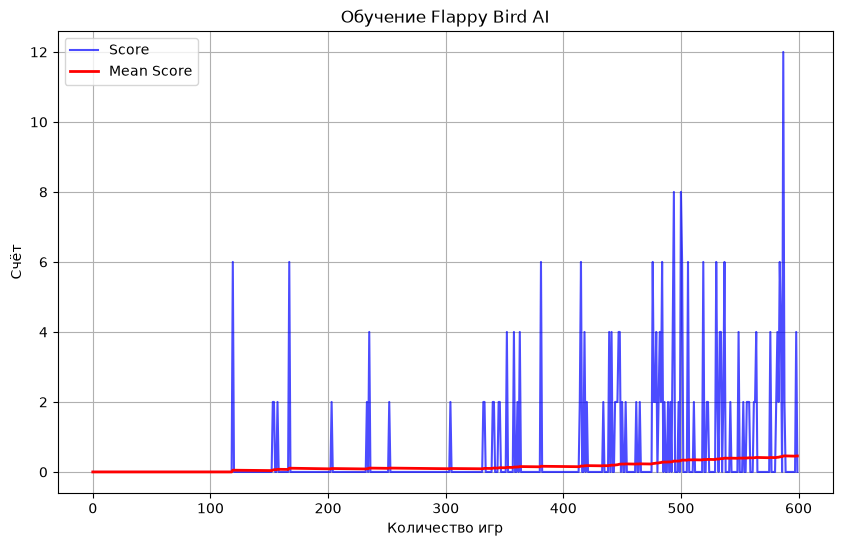

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(scoresHistory, label="Score", color='blue', alpha=0.7)
plt.plot(meanScores, label="Mean Score", color='red', linewidth=2)
plt.title("Обучение Flappy Bird AI")
plt.xlabel("Количество игр")
plt.ylabel("Счёт")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import pygame
import imageio.v2 as imageio
import tempfile
import os

def create_ai_gif(agent, gif_filename="trained_flappy_ai.gif", max_frames=1500, fps=15):
    temp_dir = tempfile.mkdtemp()
    frames = []

    game = FlappyBirdGameAi()
    game.reset()

    original_epsilon = agent.epsilon
    agent.epsilon = 0

    frame_count = 0
    score = 0

    print("🎥 Начало записи GIF...")

    try:
        while not game.game_over and frame_count < max_frames:

            for event in pygame.event.get():
                if event.type == pygame.QUIT:
                    pygame.quit()
                    return

            state = game.getState()

            action = agent.getAction(state)

            reward, done, score = game.playStep(action)

            # обновляем экран
            game.updateUi()

            # обязательно обновляем display
            pygame.display.flip()

            # получаем пиксели экрана
            frame_array = pygame.surfarray.array3d(game.display)

            # pygame -> numpy format
            frame_array = frame_array.transpose([1, 0, 2])

            # HUD
            frame_surface = pygame.surfarray.make_surface(
                frame_array.transpose([1, 0, 2])
            )

            font = pygame.font.Font(None, 30)

            score_text = font.render(
                f"Score: {score}",
                True,
                (255, 255, 0)
            )

            frame_text = font.render(
                f"Frame: {frame_count}",
                True,
                (100, 255, 255)
            )

            frame_surface.blit(score_text, (15, 15))
            frame_surface.blit(frame_text, (15, 50))

            # surface -> array
            final_frame = pygame.surfarray.array3d(frame_surface)
            final_frame = final_frame.transpose([1, 0, 2])

            frames.append(final_frame)

            frame_count += 1

            if frame_count % 50 == 0:
                print(f"Frames: {frame_count} | Score: {score}")

            if done:
                game.reset()

    except Exception as e:
        print(f"Ошибка: {e}")
    finally:
        agent.epsilon = original_epsilon

    print(f"Запись завершена! Кадров: {len(frames)}, Финальный счёт: {score}")

    if frames:

        print("Создаём GIF...")

        imageio.mimsave(
            gif_filename,
            frames,
            fps=fps
        )

        print(f"GIF сохранён: {gif_filename}")

    else:
        print("Кадры не записались")

In [ ]:
create_ai_gif(bestAgent, "trained_flappy_ai.gif", max_frames=800, fps=15)

🎥 Начало записи GIF...
Frames: 50 | Score: 0
Frames: 100 | Score: 0
Frames: 150 | Score: 0
Frames: 200 | Score: 4
Frames: 250 | Score: 0
Frames: 300 | Score: 0
Frames: 350 | Score: 0
Frames: 400 | Score: 0
Frames: 450 | Score: 0
Frames: 500 | Score: 0
Frames: 550 | Score: 0
Frames: 600 | Score: 0
Frames: 650 | Score: 0
Frames: 700 | Score: 0
Frames: 750 | Score: 0
Frames: 800 | Score: 4
Запись завершена! Кадров: 800, Финальный счёт: 4
Создаём GIF...
GIF сохранён: trained_flappy_ai.gif


Задание

Найти любую игру и реализовать обучение (кроме змейки) и визуализировать игру ИИ